In [46]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

In [47]:
empty = pd.read_csv("manual_review_sample.csv")
empty

,review_group,row_id,Rndrng_NPI,HCPCS_Cd,Place_Of_Srvc,Rndrng_Prvdr_Type,peer_level,std. payment ($),std. payment ($) peer median,std. payment ($) x median,...,charge / allowed z,above peers (z > 3.5),below peers (z < -3.5),baseline pct,IF pct,DBSCAN pct,DBSCAN noise,what stands out,plausible explanation,needs a closer look? (yes / no / unclear)
0,DBSCAN only,914899,1093415903,99306,F,Nurse Practitioner,1,85.86,119.58,0.72,...,0.5,NaN,std. payment ($),22.10,98.90,99.57,True,NaN,NaN,NaN
1,DBSCAN only,4054261,1417274465,69209,O,Family Practice,1,11.85,12.17,0.97,...,0.7,services per patient,NaN,96.18,98.82,99.19,True,NaN,NaN,NaN
2,DBSCAN only,6819261,1699743229,96127,O,Obstetrics & Gynecology,1,1.61,3.13,0.51,...,1.3,NaN,std. payment ($),49.10,98.80,99.09,True,NaN,NaN,NaN
3,DBSCAN only,8208243,1831671205,J0897,O,Nurse Practitioner,1,15.12,19.25,0.79,...,-1.0,NaN,std. payment ($),25.06,97.07,99.83,True,NaN,NaN,NaN
4,DBSCAN only,7048980,1710981196,94727,O,Critical Care (Intensivists),1,15.40,33.49,0.46,...,0.4,NaN,std. payment ($),44.07,88.62,99.81,True,NaN,NaN,NaN
5,DBSCAN only,6804196,1699485821,80061,O,Clinical Laboratory,1,13.12,13.12,1.00,...,1.2,NaN,NaN,74.64,61.08,99.94,True,NaN,NaN,NaN
6,"IF + DBSCAN, not baseline",5826827,1598706103,93010,F,Internal Medicine,1,4.38,6.03,0.73,...,2.3,NaN,std. payment ($),97.25,99.88,99.30,True,NaN,NaN,NaN
7,"IF + DBSCAN, not baseline",7097947,1720206568,99213,O,Vascular Surgery,1,51.08,66.46,0.77,...,1.8,services per patient,std. payment ($),97.10,99.77,99.43,True,NaN,NaN,NaN
8,"IF + DBSCAN, not baseline",9317859,1952362394,99215,F,Medical Oncology,1,76.29,107.48,0.71,...,-2.4,NaN,std. payment ($),4.52,99.68,99.58,True,NaN,NaN,NaN
9,"IF + DBSCAN, not baseline",6467731,1659945277,91320,O,Nurse Practitioner,1,146.15,143.91,1.02,...,1.8,services per patient,NaN,98.36,99.26,99.02,True,NaN,NaN,NaN


In [48]:
df = pd.read_csv("manual_review_sample_filled.csv")
df

,review_group,row_id,Rndrng_NPI,HCPCS_Cd,Place_Of_Srvc,Rndrng_Prvdr_Type,peer_level,std. payment ($),std. payment ($) peer median,std. payment ($) x median,...,charge / allowed z,above peers (z > 3.5),below peers (z < -3.5),baseline pct,IF pct,DBSCAN pct,DBSCAN noise,what stands out,plausible explanation,needs a closer look? (yes / no / unclear)
0,DBSCAN only,914899,1093415903,99306,F,Nurse Practitioner,1,85.86,119.58,0.72,...,0.5,NaN,std. payment ($),22.10,98.90,99.57,True,payment 0.72x peer median (z=-41.3). Percentil...,Payment about 28% under peers in a facility se...,no
1,DBSCAN only,4054261,1417274465,69209,O,Family Practice,1,11.85,12.17,0.97,...,0.7,services per patient,NaN,96.18,98.82,99.19,True,services/patient 1.63x peer median (z=5.6). Pe...,Ear irrigation/cerumen removal is often repeat...,no
2,DBSCAN only,6819261,1699743229,96127,O,Obstetrics & Gynecology,1,1.61,3.13,0.51,...,1.3,NaN,std. payment ($),49.10,98.80,99.09,True,payment 0.51x peer median (z=-5.8). Percentile...,Brief screening/assessment code with a payment...,no
3,DBSCAN only,8208243,1831671205,J0897,O,Nurse Practitioner,1,15.12,19.25,0.79,...,-1.0,NaN,std. payment ($),25.06,97.07,99.83,True,payment 0.79x peer median (z=-20.3). Percentil...,Drug-injection (J-code) payment varies with pr...,no
4,DBSCAN only,7048980,1710981196,94727,O,Critical Care (Intensivists),1,15.40,33.49,0.46,...,0.4,NaN,std. payment ($),44.07,88.62,99.81,True,payment 0.46x peer median (z=-13.7). Percentil...,Unusual specialty for this lung-function test ...,unclear
5,DBSCAN only,6804196,1699485821,80061,O,Clinical Laboratory,1,13.12,13.12,1.00,...,1.2,NaN,NaN,74.64,61.08,99.94,True,no feature beyond |z|>3.5; largest gap is pati...,High-volume clinical lab (12.7x patients) with...,no
6,"IF + DBSCAN, not baseline",5826827,1598706103,93010,F,Internal Medicine,1,4.38,6.03,0.73,...,2.3,NaN,std. payment ($),97.25,99.88,99.30,True,payment 0.73x peer median (z=-6.5). Percentile...,ECG interpretation in a facility setting; paym...,no
7,"IF + DBSCAN, not baseline",7097947,1720206568,99213,O,Vascular Surgery,1,51.08,66.46,0.77,...,1.8,services per patient,std. payment ($),97.10,99.77,99.43,True,payment 0.77x peer median (z=-5.1); services/p...,Established-patient visits at 2.65x median per...,unclear
8,"IF + DBSCAN, not baseline",9317859,1952362394,99215,F,Medical Oncology,1,76.29,107.48,0.71,...,-2.4,NaN,std. payment ($),4.52,99.68,99.58,True,payment 0.71x peer median (z=-9.8). Percentile...,Below-peer on payment and charges only; baseli...,no
9,"IF + DBSCAN, not baseline",6467731,1659945277,91320,O,Nurse Practitioner,1,146.15,143.91,1.02,...,1.8,services per patient,NaN,98.36,99.26,99.02,True,services/patient 1.3x peer median (z=8.5). Per...,Method artifact: vaccine code with fixed prici...,no


   HCPCS_Cd                   Rndrng_Prvdr_Type  both_yes
17    99214                 Physician Assistant      True
21    82570                  Nurse Practitioner      True
22    99212                 Physician Assistant     False
23    90791              Psychologist, Clinical      True
35    99213                 Physician Assistant     False
44    Q4191  Plastic and Reconstructive Surgery      True
46    82550                          Nephrology      True


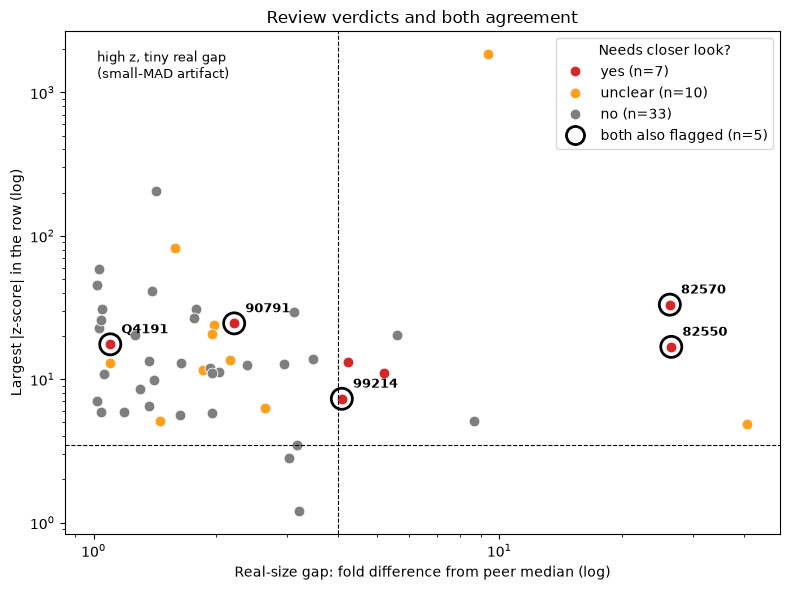

In [49]:
VERDICT = "needs a closer look? (yes / no / unclear)"
features = ["std. payment ($)", "patients", "services per patient", "charge / allowed"]

# Records flagged for further review by both (HCPCS code, provider type)
both = [("99214", "Physician Assistant"), ("82570", "Nurse Practitioner"),
           ("90791", "Psychologist, Clinical"), ("Q4191", "Plastic and Reconstructive Surgery"),
           ("82550", "Nephrology")]
df["both_yes"] = [any(str(r.HCPCS_Cd) == c and r.Rndrng_Prvdr_Type == t for c, t in both)
                     for r in df.itertuples()]

z = df[[f + " z" for f in features]].abs()
x = df[[f + " x median" for f in features]]
driver = z.fillna(-1).values.argmax(axis=1)
df["max_abs_z"] = z.values[np.arange(len(df)), driver]
ratio = x.values[np.arange(len(df)), driver]
df["fold_gap"] = np.exp(np.abs(np.log(ratio)))

colors = {"yes": "#d62728", "unclear": "#ff9f1c", "no": "#7f7f7f"}
fig, ax = plt.subplots(figsize=(8, 6))

# z-score vs real-size gap
for v, c in colors.items():
    s = df[df[VERDICT] == v]
    ax.scatter(s["fold_gap"], s["max_abs_z"], c=c, s=60, edgecolor="white", linewidth=0.6, zorder=2)
p = df[df.both_yes]
ax.scatter(p["fold_gap"], p["max_abs_z"], s=230, facecolor="none", edgecolor="black",
           linewidth=2, zorder=3)
for r in p.itertuples():
    ax.annotate(r.HCPCS_Cd, (r.fold_gap, r.max_abs_z), xytext=(8, 8),
                textcoords="offset points", fontsize=9, fontweight="bold")
ax.set_xscale("log"); ax.set_yscale("log")
ax.axhline(3.5, ls="--", c="k", lw=0.8); ax.axvline(4, ls="--", c="k", lw=0.8)
ax.text(1.02, 2000, "high z, tiny real gap\n(small-MAD artifact)", fontsize=9, va="top")
ax.set_xlabel("Real-size gap: fold difference from peer median (log)")
ax.set_ylabel("Largest |z-score| in the row (log)")
ax.set_title("Review verdicts and both agreement")
n_yes, n_both = (df[VERDICT] == "yes").sum(), (df.both_yes & (df[VERDICT] == "yes")).sum()
handles = [Line2D([], [], marker="o", ls="", color=colors["yes"], label=f"yes (n={n_yes})"),
           Line2D([], [], marker="o", ls="", color=colors["unclear"], label=f"unclear (n={(df[VERDICT]=='unclear').sum()})"),
           Line2D([], [], marker="o", ls="", color=colors["no"], label=f"no (n={(df[VERDICT]=='no').sum()})"),
           Line2D([], [], marker="o", ls="", markerfacecolor="none", markeredgecolor="black",
                  markeredgewidth=2, markersize=13, label=f"both also flagged (n={n_both})")]
ax.legend(handles=handles, title="Needs closer look?")

plt.tight_layout()
plt.savefig("review_summary.png", dpi=150)
print(df[df[VERDICT]=="yes"][["HCPCS_Cd","Rndrng_Prvdr_Type","both_yes"]])